# Clamped and face-clamped edges

This example compares two ways of clamping a thick plate: the clamp of the boundary condition flags and a clamp by the faces of the edge, imposed with prescribed displacements. It shows the warping of the section that the face clamp allows in the third-order shear deformation theory.

In the classical laminated plate theory (CLPT), a clamped edge $x = 0$ has $u = v = w = 0$ and $w_{,x} = 0$. In the first-order shear deformation theory (FSDT), the rotations $\phi_x$, $\phi_y$ replace the slope. The third-order theory (TSDT) of Reddy (1984) has the in-plane displacements

$$
u(z) = u_0 + z\phi_x - c_1 z^3 (\phi_x + w_{,x}), \qquad c_1 = \frac{4}{3h^2},
$$

about the mid-surface. With the flags, a clamped TSDT edge has `x1wr = 0` together with `x1phix = x1phiy = 0`, so the cross-section stays planar and unrotated. An edge clamped by its faces has $u = v = 0$ at $z = d \mp h/2$ and $w = 0$, where $d$ is the offset of the mid-surface from the reference surface. This leaves the section free to warp. It is prescribed with the keyword `z` of `Shell.add_distr_pd_fixed_x`, see [Boundary conditions](../boundary_conditions.rst).

The square plates below, $a = b = 0.5$ m, $h = 0.05$ m ($h/a = 0.1$), $E = 70$ GPa, $\nu = 0.3$, are clamped at $x = 0, a$, free at $y = 0, b$, and loaded by a uniform pressure $q = 1$ MPa. The prescribed displacements are imposed exactly by a `MultiDomain` with `pd_method='null-space'`.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from structsolve import solve
from structsolve.sparseutils import finalize_symmetric_matrix
from panels.shell import Shell
from panels.multidomain import MultiDomain
from panels.multidomain.connections import fkCld_xcte


def results_table(rows):
    """Markdown table of (quantity, panels, reference, source) rows"""
    out = ['| quantity | panels | reference | relative difference | reference source |',
           '|---|---|---|---|---|']
    for name, val, ref, src in rows:
        out.append('| %s | %.6g | %.6g | %+.2e | %s |'
                   % (name, val, ref, (val - ref)/abs(ref), src))
    display(Markdown('\n'.join(out)))

## Model

`plate` builds a plate with all edges free and the pressure load. `clamp_by_flags` constrains all the fields at an edge and, except for the FSDT, the slope of $w$. `face_clamp` prescribes $u = v = 0$ at the two faces of the edge $x$ and $w = 0$. `fields` evaluates the displacements, the rotations and the transverse shear strains at given points, and `uv_at` the in-plane displacements at a thickness coordinate $z$ with the kinematics above.

In [2]:
A = B = 0.5
H = 0.05
E, NU = 70e9, 0.3
Q = 1e6
D = E*H**3/(12*(1 - NU**2))
FIELDS = ('u', 'v', 'w', 'phix', 'phiy')


def plate(model, offset=0., m=10, n=10):
    s = Shell(model=model, a=A, b=B, stack=[0.], plyt=H, laminaprop=(E, NU),
              offset=offset, m=m, n=n)
    for edge in ('x1', 'x2', 'y1', 'y2'):
        for field in FIELDS:
            setattr(s, edge + field, 1.)
            setattr(s, edge + field + 'r', 1.)
    s.add_pressure_load(Q)
    return s


def clamp_by_flags(s, edge):
    for field in FIELDS:
        setattr(s, edge + field, 0.)
    if 'fsdt' not in s.model:
        setattr(s, edge + 'wr', 0.)


def face_clamp(s, x, k=1., cte=True):
    zero = lambda y: 0.
    for z in (s.offset - H/2, s.offset + H/2):
        s.add_distr_pd_fixed_x(x, ku=k, kv=k, funcu=zero, funcv=zero, z=z,
                               cte=cte)
    s.add_distr_pd_fixed_x(x, kw=k, funcw=zero, cte=cte)


def static(s, pd_method='null-space'):
    md = MultiDomain([s], conn=[], pd_method=pd_method)
    return md.linear_static()


def fields(s, c, xs, ys):
    xs = np.atleast_1d(np.asarray(xs, dtype=float))
    ys = np.atleast_1d(np.asarray(ys, dtype=float))
    s.uvw(c, xs=xs, ys=ys)
    out = {k: s.fields[k].ravel().copy() for k in FIELDS}
    if 'clpt' in s.model:
        out['gxz'] = out['gyz'] = 0*out['u']
    else:
        s.strain(c, xs=xs, ys=ys, NLgeom=False)
        out['gxz'] = s.fields['gxz'].ravel().copy()
        out['gyz'] = s.fields['gyz'].ravel().copy()
    return out


def uv_at(s, f, z):
    c1 = 4/(3*H**2) if 'tsdt' in s.model else 0.
    d = s.offset
    p = -c1*((z - d)**3 + d**3)
    return (f['u'] + z*f['phix'] + p*f['gxz'],
            f['v'] + z*f['phiy'] + p*f['gyz'])


xs, ys = [g.ravel() for g in np.meshgrid(np.linspace(0, A, 7),
                                          np.linspace(0, B, 5))]

## CLPT and FSDT: the face clamp is the clamp of the flags

In these theories the displacements are linear in $z$. Zero displacements at both faces then mean zero displacement and zero rotation of the whole section, so the face clamp and the clamp of the flags give the same solution.

In [3]:
for model in ['plate_clpt_donnell', 'plate_fsdt_donnell']:
    s = plate(model)
    for x in (0., A):
        face_clamp(s, x)
    c = static(s)
    t = plate(model)
    clamp_by_flags(t, 'x1')
    clamp_by_flags(t, 'x2')
    ct = static(t)
    f, ft = fields(s, c, xs, ys), fields(t, ct, xs, ys)
    diff = max(np.abs(f[k] - ft[k]).max() for k in FIELDS)
    print('%-20s largest difference of the fields: %.1e of the largest w'
          % (model, diff/np.abs(ft['w']).max()))

plate_clpt_donnell   largest difference of the fields: 0.0e+00 of the largest w
plate_fsdt_donnell   largest difference of the fields: 0.0e+00 of the largest w


## TSDT: planar clamp, face clamp and simple support

In the TSDT, $u(z)$ is cubic. Prescribing $u = v = 0$ at a third thickness coordinate besides the faces, here $z = d + h/4$, forces $\phi_x + w_{,x} = 0$ and gives the planar clamp of the flags. The face clamp alone lets the section warp, and lies between the planar clamp and the simple support, where $u = v = w = \phi_y = 0$ at $x = 0, a$.

The reference values of the non-dimensional central deflections $w D/(q a^4)$ are regression values of the panels unit test `tests/multidomain/test_face_clamp.py`, checked there within $2 \times 10^{-4}$; no literature value is available for this thick plate with free edges.

In [4]:
model = 'plate_tsdt_donnell'
face = plate(model)
for x in (0., A):
    face_clamp(face, x)
c_face = static(face)

planar = plate(model)
clamp_by_flags(planar, 'x1')
clamp_by_flags(planar, 'x2')
c_planar = static(planar)

u_three = plate(model)
for x in (0., A):
    face_clamp(u_three, x)
    u_three.add_distr_pd_fixed_x(x, ku=1., kv=1., funcu=lambda y: 0.,
                                 funcv=lambda y: 0., z=H/4)
c_three = static(u_three)

ss = plate(model)
for edge in ('x1', 'x2'):
    for field in ('u', 'v', 'w', 'phiy'):
        setattr(ss, edge + field, 0.)
c_ss = static(ss)

f3, fp = fields(u_three, c_three, xs, ys), fields(planar, c_planar, xs, ys)
print('u = 0 at three coordinates vs planar clamp: largest difference %.1e '
      'of the largest w' % (max(np.abs(f3[k] - fp[k]).max() for k in FIELDS)
                            / np.abs(fp['w']).max()))
center = {}
for name, s, c in (('planar clamp', planar, c_planar),
                   ('face clamp', face, c_face),
                   ('simple support', ss, c_ss)):
    center[name] = fields(s, c, A/2, B/2)['w'][0]*D/(Q*A**4)
    print('%-15s w D/(q a^4) = %.6f' % (name, center[name]))
results_table([
    ('planar clamp, $w D/(q a^4)$', center['planar clamp'], 0.002901,
     'regression value, `test_face_clamp.py`'),
    ('face clamp, $w D/(q a^4)$', center['face clamp'], 0.002953,
     'regression value, `test_face_clamp.py`'),
    ('simple support, $w D/(q a^4)$', center['simple support'], 0.013459,
     'regression value, `test_face_clamp.py`'),
])

u = 0 at three coordinates vs planar clamp: largest difference 0.0e+00 of the largest w
planar clamp    w D/(q a^4) = 0.002901
face clamp      w D/(q a^4) = 0.002953
simple support  w D/(q a^4) = 0.013459


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| planar clamp, $w D/(q a^4)$ | 0.00290111 | 0.002901 | +3.65e-05 | regression value, `test_face_clamp.py` |
| face clamp, $w D/(q a^4)$ | 0.00295285 | 0.002953 | -5.23e-05 | regression value, `test_face_clamp.py` |
| simple support, $w D/(q a^4)$ | 0.0134591 | 0.013459 | +6.40e-06 | regression value, `test_face_clamp.py` |

The deflection along the center line $y = b/2$, and the in-plane displacement $u(z)$ through the thickness at the clamped edge $x = 0$, at $y = b/2$. With the face clamp $u$ vanishes at the faces and not inside, while the planar clamp keeps the whole section fixed:

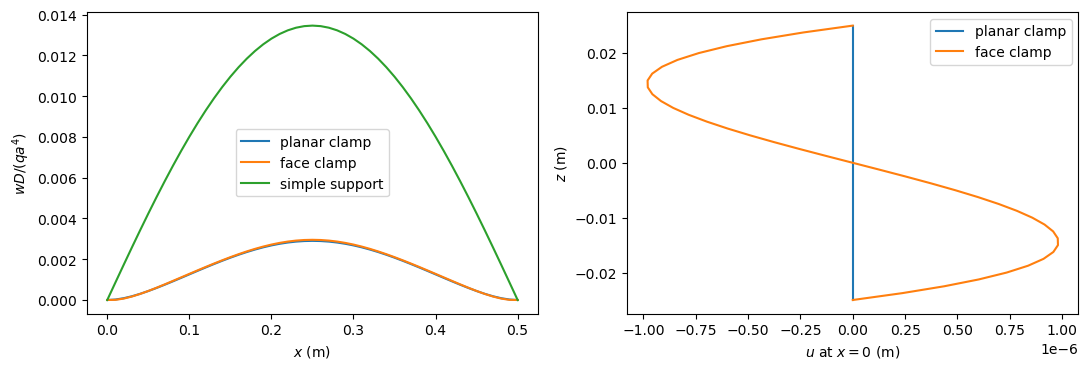

In [5]:
xl = np.linspace(0, A, 51)
zs = np.linspace(-H/2, H/2, 41)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name, s, c in (('planar clamp', planar, c_planar),
                   ('face clamp', face, c_face),
                   ('simple support', ss, c_ss)):
    w = fields(s, c, xl, np.full_like(xl, B/2))['w']
    axes[0].plot(xl, w*D/(Q*A**4), label=name)
    if name != 'simple support':
        f = fields(s, c, [0.], [B/2])
        axes[1].plot([uv_at(s, f, z)[0][0] for z in zs], zs, label=name)
axes[0].set_xlabel('$x$ (m)')
axes[0].set_ylabel('$w D/(q a^4)$')
axes[0].legend()
axes[1].set_xlabel('$u$ at $x = 0$ (m)')
axes[1].set_ylabel('$z$ (m)')
axes[1].legend()
fig.tight_layout()
plt.show()

At the face-clamped edge the section warps with $\phi_x = w_{,x}/2$, so that $\gamma_{xz} = 3\phi_x$ there, and

$$
u(z) = \frac{w_{,x}}{2}\, z \left(1 - \frac{4 z^2}{h^2}\right),
$$

which vanishes at $z = \pm h/2$. The value at $z = h/4$ is compared with this expression:

In [6]:
f = fields(face, c_face, np.zeros(11), np.linspace(0, B, 11))
u_h4 = uv_at(face, f, H/4)[0]
ref_h4 = f['gxz']/3*H/4*(1 - 4*(H/4)**2/H**2)
print('largest |u| at the faces: %.1e m, largest |u| at z = h/4: %.3e m'
      % (np.abs(uv_at(face, f, H/2)[0]).max(), np.abs(u_h4).max()))
print('largest |gxz - 3 phix|: %.1e' % np.abs(f['gxz'] - 3*f['phix']).max())
i = np.argmax(np.abs(u_h4))
results_table([('$u(h/4)$ at $x = 0$, $y = %.2f$ (m)' % np.linspace(0, B, 11)[i],
                u_h4[i], ref_h4[i],
                r'$(w_{,x}/2) z (1 - 4z^2/h^2)$, with $\gamma_{xz} = 3\phi_x$')])

largest |u| at the faces: 1.1e-19 m, largest |u| at z = h/4: 1.794e-06 m
largest |gxz - 3 phix|: 9.8e-18


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| $u(h/4)$ at $x = 0$, $y = 0.50$ (m) | -1.79362e-06 | -1.79362e-06 | -4.01e-15 | $(w_{,x}/2) z (1 - 4z^2/h^2)$, with $\gamma_{xz} = 3\phi_x$ |

## Independence of the reference surface

Both clamps are defined by the physical section. The deflections do not depend on the offset $d$ of the reference surface:

In [7]:
res = {}
for offset in (0., 0.3*H, 0.5*H):
    s = plate(model, offset)
    for x in (0., A):
        face_clamp(s, x)
    t = plate(model, offset)
    clamp_by_flags(t, 'x1')
    clamp_by_flags(t, 'x2')
    res[offset] = (fields(s, static(s), xs, ys)['w'],
                   fields(t, static(t), xs, ys)['w'])
for offset in (0.3*H, 0.5*H):
    print('offset %.3f m: largest relative change of w, face clamp %.1e, '
          'planar clamp %.1e' % (offset,
          *[np.abs(res[offset][i] - res[0.][i]).max()/np.abs(res[0.][i]).max()
            for i in (0, 1)]))

offset 0.015 m: largest relative change of w, face clamp 1.5e-12, planar clamp 2.7e-12
offset 0.025 m: largest relative change of w, face clamp 1.5e-12, planar clamp 1.3e-12


## Penalty method

With the penalty method, the springs of the prescribed displacements, `fkCld_xcte`, are given the same `z` and added to the stiffness matrix by the user. With a stiffness of $10^4 E$, the face clamp at $x = 0$ and a shortening $\delta = 10^{-5}$ m of both faces at $x = a$ give the solution of the null-space method:

In [8]:
delta = 1e-5


def build(k, offset=0.):
    s = plate(model, offset)
    face_clamp(s, 0., k=k)
    for z in (offset - H/2, offset + H/2):
        s.add_distr_pd_fixed_x(A, ku=k, kv=k, funcu=lambda y: -delta,
                               funcv=lambda y: 0., z=z)
    s.add_distr_pd_fixed_x(A, kw=k, funcw=lambda y: 0.)
    return s


s = build(1.)
c = static(s)
k = 1e4*E
p = build(k)
md = MultiDomain([p], conn=[])
size = md.get_size()
kCp = 0
for x in (0., A):
    for z in (-H/2, H/2):
        kCp = kCp + fkCld_xcte(k, k, 0., p, x, size, 0, 0, z=z)
    kCp = kCp + fkCld_xcte(0., 0., k, p, x, size, 0, 0)
K = md.calc_kC() + finalize_symmetric_matrix(kCp)
cp = solve(K, md.calc_fext(), silent=True)
f, fpen = fields(s, c, xs, ys), fields(p, cp, xs, ys)
for key in ('u', 'w'):
    print('largest difference of %s, penalty vs null-space: %.1e of the '
          'largest' % (key, np.abs(fpen[key] - f[key]).max()
                       / np.abs(f[key]).max()))
fa = fields(s, c, np.full(5, A), np.linspace(0, B, 5))
u_face = uv_at(s, fa, H/2)[0]
results_table([('$u$ of the face $z = h/2$ at $x = a$ (m)', u_face.mean(),
                -delta, 'prescribed value')])

largest difference of u, penalty vs null-space: 1.1e-05 of the largest
largest difference of w, penalty vs null-space: 1.4e-05 of the largest


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| $u$ of the face $z = h/2$ at $x = a$ (m) | -1e-05 | -1e-05 | +6.78e-15 | prescribed value |

## References

1. J. N. Reddy, "A simple higher-order theory for laminated composite plates". Journal of Applied Mechanics, 51(4):745-752, 1984. https://doi.org/10.1115/1.3167719.